# Emulación de dispersión cromática en el punto de diseño del compensador

En este avance se evalúa el bloque de dispersión cromática (CD) del emulador de canal óptico con los parámetros de diseño que utiliza el grupo del compensador de CD. Se sigue la señal a lo largo de toda la cadena: desde la generación de los símbolos 16-QAM en el transmisor, pasando por la fibra emulada, hasta la recepción, con muestreo en una grilla fija y con sincronización ideal. El análisis se hace primero en el punto de diseño (60 GBd, 200 km) y después para distintas tasas de símbolos y distancias.

La señal no se compensa: el objetivo es mostrar el efecto que produce el bloque de CD sobre la señal recibida, que es lo que el compensador del grupo debe deshacer. El algoritmo del compensador no se reproduce aquí.

## 1. Parámetros de simulación

Se adoptan los parámetros presentados por el grupo del compensador. La pendiente de dispersión no figuraba en la presentación original, pero el grupo mostró luego resultados que la incluyen, por lo que se considera con el valor típico de una fibra monomodo estándar (SSMF).

| Parámetro | Valor |
|---|---|
| Tasa de símbolos | 60 GBd |
| Frecuencia de muestreo | 72 GSa/s (1,2 muestras por símbolo) |
| Modulación | 16-QAM con codificación Gray |
| Conformación | coseno realzado, roll-off 0,1, 300 símbolos |
| Largo de la secuencia | 10 000 símbolos |
| Fibra | SSMF, 200 km, $D$ = 17 ps/(nm·km), $\lambda$ = 1550 nm |
| Pendiente de dispersión | $S$ = 0,057 ps/(nm²·km) |
| Ventana FFT del compensador | 384 muestras |

Para el análisis en función de la tasa y la distancia se mantiene el sobremuestreo de 1,2 muestras por símbolo y se consideran 32, 60 y 100 GBd (38,4, 72 y 120 GSa/s). Como sin compensación la constelación se pierde en pocos kilómetros, las distancias incluyen tramos cortos: 2, 5, 20 y 200 km, y un barrido de 1 a 1000 km.

La relación señal a ruido del enlace (OSNR de 20 dB) no se incluye en este análisis: en la cadena del emulador el ruido se agrega después del canal, en un bloque independiente.

In [ ]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import minimize_scalar
from scipy.signal import resample_poly, welch

from emulador import plots
from emulador.blocks import ChromaticDispersion
from emulador.cd import betas, cd_N, cd_R, cd_reference
from emulador.config import C, D_si, S_si
from emulador.metrics import evm_opt, group_delay, nrmse
from emulador.stimuli import map_gray, prbs

plots.use_style()

# Parámetros del punto de diseño
RS = 60e9                 # tasa de símbolos [Bd]
OS = 1.2                  # muestras por símbolo
FS = OS * RS              # frecuencia de muestreo [Sa/s]
ROLLOFF, SPAN = 0.1, 300  # coseno realzado
N_SYM = 10_000
D_PS = 17.0               # ps/(nm km)
S_PS = 0.057              # ps/(nm^2 km)
LAM_NM = 1550.0
Z_KM = 200.0
B_CDC = 384               # ventana FFT del compensador

# Barrido de tasas y distancias
RS_LIST = (32e9, 60e9, 100e9)
Z_LIST = (2.0, 5.0, 20.0, 200.0)

# Conversión a unidades SI
D, S = D_si(D_PS), S_si(S_PS)
lam, z = LAM_NM / 1e9, Z_KM * 1e3

## 2. Modelo de dispersión cromática

La fibra se modela como un filtro pasa-todo sobre la envolvente compleja de la señal:

$$
H(\omega) = \exp\left[-j\left(\frac{\beta_2}{2}\,\omega^2 + \frac{\beta_3}{6}\,\omega^3\right) z\right],
\qquad
\beta_2 = -\frac{D\lambda^2}{2\pi c},
\qquad
\beta_3 = \left(\frac{\lambda^2}{2\pi c}\right)^2\left(S + \frac{2D}{\lambda}\right).
$$

Sin el término de tercer orden, $H(f) = \exp\left(j\pi D\lambda^2 z f^2/c\right)$, que es la expresión utilizada por Jiang, Xie y Chen [1] para su emulador de CD en FPGA. El retardo de grupo resultante es aproximadamente lineal en frecuencia, $\tau(f) \approx -D\lambda^2 z f/c$: las distintas componentes espectrales llegan en instantes diferentes y cada símbolo se superpone con sus vecinos.

El emulador aplica $H$ mediante convolución por bloques (overlap-save) con una FFT de $2N$ puntos, que es la estructura prevista para el hardware. La respuesta al impulso de la CD ocupa aproximadamente

$$
R = 2\left\lfloor \frac{|D|\lambda^2 z}{2cT_s^2}\right\rfloor + 1
$$

muestras, y el método requiere $N \ge R$. El emulador elige automáticamente la menor potencia de 2 que cumple esa condición, con un mínimo de 128.

In [ ]:
b2, b3 = betas(D, lam, S)
R = cd_R(FS, D, lam, z)
N = cd_N(FS, D, lam, z)
# Borde de la banda de la señal y retardo de grupo en ese punto
edge = (1 + ROLLOFF) * RS / 2
tau_edge = D * lam**2 * z * edge / C

print(f"beta2 = {b2 / 1e-27:.2f} ps^2/km, beta3 = {b3 / 1e-39:.3f} ps^3/km")
print(f"Banda de la señal: +/-{edge / 1e9:.0f} GHz")
print(f"Retardo de grupo en el borde: +/-{tau_edge * 1e12:.0f} ps "
      f"(+/-{tau_edge * RS:.0f} símbolos)")
print(f"Respuesta al impulso: R = {R} muestras")
print(f"Bloque del emulador: N = {N}, retardo N/2 = {N // 2} muestras")
print(f"Ventana del compensador: hasta {B_CDC // 2 + 1} muestras")

## 3. Cadena de simulación

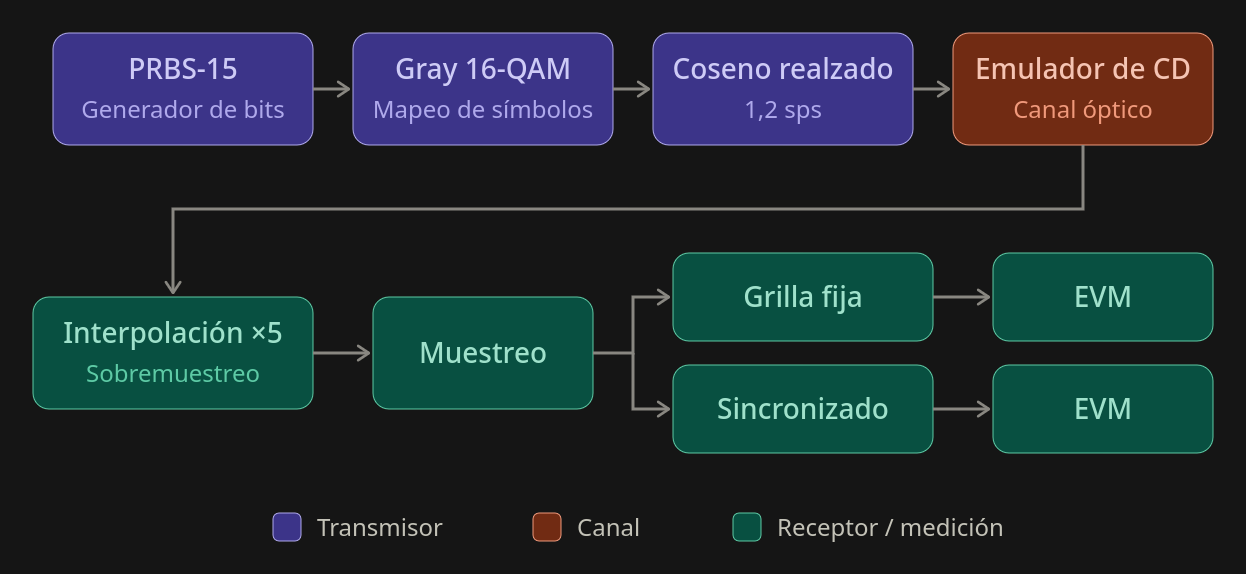

**Transmisor.** Los símbolos se obtienen de una secuencia PRBS-15 con mapeo Gray a 16-QAM y potencia media unitaria. Como el emulador no trabaja nativamente con 1,2 muestras por símbolo, la señal se conforma a 6 muestras por símbolo con el filtro de coseno realzado y luego se toma una de cada cinco muestras. Esta decimación no introduce aliasing: en el punto de diseño la señal ocupa ±33 GHz y la frecuencia de Nyquist es de 36 GHz.

**Canal.** El bloque `ChromaticDispersion` del emulador aplica $H$ con $\beta_2$ y $\beta_3$ y el tamaño de bloque automático.

**Receptor.** La salida del emulador, sin compensar, se interpola a 6 muestras por símbolo y se toma una muestra por símbolo. Como el transmisor usa coseno realzado completo, que cumple el criterio de Nyquist, no hace falta filtro adaptado. Se consideran dos receptores:

- **Grilla fija:** se muestrea en los instantes nominales $kT$, sin corrección de temporización.
- **Sincronizado:** antes de muestrear se busca el retardo fraccionario continuo que minimiza la EVM, lo que equivale a una recuperación de temporización ideal.

Comparar los dos receptores permite separar un error de temporización de una distorsión de la señal: si la degradación se debiera a un corrimiento temporal, el receptor sincronizado la corregiría.

La EVM se calcula con ganancia compleja óptima, que corrige la amplitud y la rotación de fase de la constelación. Se descartan en cada extremo 200 símbolos más los que ocupa la respuesta al impulso de la CD ($R$ muestras), donde la señal transmitida, de largo finito, no llega a estar completa.

In [ ]:
UP, DOWN = 6, 5   # 6 muestras por símbolo y decimación por 5: 1,2 muestras por símbolo
DISCARD = 200     # símbolos descartados en cada extremo, además de la respuesta de la CD


def raised_cosine(beta, span, sps):
    t = np.arange(-span * sps // 2, span * sps // 2 + 1) / sps
    h = np.sinc(t) * np.cos(np.pi * beta * t)
    den = 1 - (2 * beta * t) ** 2
    # en t = ±1/(2β) la expresión es 0/0 y se usa el valor límite
    sing = np.isclose(den, 0)
    h[~sing] /= den[~sing]
    h[sing] = np.pi / 4 * np.sinc(1 / (2 * beta))
    return h


def to_6sps(y):
    # 1,2 -> 6 muestras por símbolo (interpolación polifásica)
    return resample_poly(y, DOWN, 1)[: N_SYM * UP]


def fractional_delay(y, tau):
    # adelanta la señal tau muestras (tau real) en el dominio de la frecuencia
    f = np.fft.fftfreq(y.size)
    return np.fft.ifft(np.fft.fft(y) * np.exp(2j * np.pi * f * tau))


def rx_symbols(y, tau=0.0):
    # una muestra por símbolo en los instantes kT (grilla fija si tau = 0)
    return to_6sps(fractional_delay(y, tau) if tau else y)[::UP]


def synchronize(y, discard):
    # retardo fraccionario de menor EVM: búsqueda en ±1 muestra y refinamiento
    def at(t):
        return evm_opt(rx_symbols(y, t), sym, discard)
    taus = np.linspace(-1, 1, 41)
    e = [at(t) for t in taus]
    i = int(np.argmin(e))
    fine = minimize_scalar(at, bounds=(taus[i] - 0.05, taus[i] + 0.05),
                           method="bounded", options={"xatol": 1e-4})
    return fine.x if fine.fun < e[i] else taus[i]


def corrected(s_rx, discard):
    # símbolos con la ganancia compleja óptima (la misma que usa evm_opt), para graficar
    s_rx, s_ref = s_rx[discard:-discard], sym[discard:-discard]
    return np.vdot(s_rx, s_ref) / np.vdot(s_rx, s_rx) * s_rx, s_ref


def transmit(rs):
    # señal 16-QAM a 1,2 muestras por símbolo, potencia media 1 (la forma no depende de rs)
    up = np.zeros(N_SYM * UP, complex)
    up[::UP] = sym
    x = np.convolve(up, raised_cosine(ROLLOFF, SPAN, UP), mode="same")[::DOWN]
    return x / np.sqrt(np.mean(np.abs(x) ** 2))


def chain(rs, z_km):
    # transmisor -> emulador -> receptor, sin compensar la CD
    fs, zz = OS * rs, z_km * 1e3
    x = transmit(rs)
    blk = ChromaticDispersion(fs=fs, D_ps_nm_km=D_PS, wavelength_nm=LAM_NM,
                              length_km=z_km, S_ps_nm2_km=S_PS)
    y = blk(x)
    discard = DISCARD + int(np.ceil(cd_R(fs, D, lam, zz) / OS))
    tau = synchronize(y, discard)
    # ensanchamiento: diferencia de retardo de grupo entre los bordes de la banda, en símbolos
    spread = abs(D) * lam**2 * zz * (1 + ROLLOFF) * rs**2 / C
    return dict(rs=rs, z_km=z_km, fs=fs, x=x, y=y, N=blk.N, R=cd_R(fs, D, lam, zz),
                discard=discard, tau=tau, spread=spread,
                nrmse=nrmse(y[blk.N:-blk.N], cd_reference(x, fs, D, lam, zz, S=S)[blk.N:-blk.N]),
                evm_grid=evm_opt(rx_symbols(y), sym, discard),
                evm_sync=evm_opt(rx_symbols(y, tau), sym, discard))


sym = map_gray(prbs(15, 4 * N_SYM), "qam16")

## 4. Transformación de la señal en el punto de diseño

### 4.1 Transmisor

In [ ]:
x = transmit(RS)
evm_b2b = evm_opt(rx_symbols(x), sym, DISCARD)
print(f"{x.size} muestras, EVM sin canal = {100 * evm_b2b:.2f} %")

fig, axs = plt.subplots(2, 2, figsize=(11, 9))
plots.constellation(axs[0, 0], sym[:2000], ref=sym, title="Símbolos 16-QAM transmitidos")

# Forma de onda: parte real a 6 muestras por símbolo, con las muestras a 1,2 sps y los símbolos
n_show = 30
x6 = to_6sps(x)
axs[0, 1].plot(np.arange(n_show * UP) / UP, x6[: n_show * UP].real, lw=1, label="señal (interpolada)")
k = np.arange(int(n_show * OS))
axs[0, 1].plot(k / OS, x[k].real, "o", ms=3, label="muestras a 1,2 sps")
g = np.sqrt(np.mean(np.abs(x6[::UP]) ** 2) / np.mean(np.abs(sym) ** 2))
axs[0, 1].plot(np.arange(n_show), g * sym[:n_show].real, "x", color="k", label="símbolos (escalados)")
axs[0, 1].set_xlabel("t / T (símbolos)")
axs[0, 1].set_ylabel("parte real")
axs[0, 1].set_title("Señal transmitida")
axs[0, 1].legend(loc="lower right", fontsize=8)

f, p = welch(x, fs=FS, nperseg=2048, return_onesided=False)
o = np.argsort(f)
axs[1, 0].plot(f[o] / 1e9, 10 * np.log10(p[o] / p.max()))
for sgn in (-1, 1):
    axs[1, 0].axvline(sgn * edge / 1e9, ls="--", color="C1", lw=0.8)
axs[1, 0].set_ylim(-80, 3)
axs[1, 0].set_xlabel("f [GHz]")
axs[1, 0].set_ylabel("PSD normalizada [dB]")
axs[1, 0].set_title("Espectro (±fs/2 = ±36 GHz)")

plots.eye(axs[1, 1], x6[DISCARD * UP:], UP, offset=UP // 2, title="Diagrama de ojo (parte real)")
plt.show()

La constelación transmitida tiene los 16 puntos de la 16-QAM con potencia media unitaria. En el tiempo, la señal conformada pasa por los valores de los símbolos en los instantes $kT$, y entre ellos queda definida por el coseno realzado. Con 1,2 muestras por símbolo, las muestras de la señal no coinciden con esos instantes salvo una de cada seis; el receptor interpola para volver a ellos. El espectro ocupa ±33 GHz, con 3 GHz de margen hasta la frecuencia de Nyquist, y el diagrama de ojo está completamente abierto en el instante de muestreo. La EVM sin canal, de 0,15 %, es el piso de esta cadena (truncamiento del filtro e interpolación del receptor).

### 4.2 Fibra emulada

Se aplican 200 km de dispersión con el bloque del emulador y se compara el resultado con una referencia ideal que aplica la misma función de transferencia con una única FFT sobre toda la señal, sin dividirla en bloques. La diferencia entre ambas se cuantifica con el error cuadrático medio normalizado (NRMSE).

In [ ]:
d = chain(RS, Z_KM)
cd = ChromaticDispersion(fs=FS, D_ps_nm_km=D_PS, wavelength_nm=LAM_NM,
                         length_km=Z_KM, S_ps_nm2_km=S_PS)
y = d["y"]
print(f"NRMSE respecto de la referencia: {d['nrmse']:.1e}")

fig, axs = plt.subplots(2, 1, figsize=(10, 8))

for sig, label, style in ((y, "salida (200 km)", dict(color="C1", lw=1)),
                          (x, "entrada", dict(color="k", lw=1.6, ls="--"))):
    f, p = welch(sig, fs=FS, nperseg=2048, return_onesided=False)
    o = np.argsort(f)
    axs[0].plot(f[o] / 1e9, 10 * np.log10(p[o] / p.max()), label=label, **style)
for sgn in (-1, 1):
    axs[0].axvline(sgn * edge / 1e9, ls="--", color="k", lw=0.8)
axs[0].set_ylim(-80, 3)
axs[0].set_xlabel("f [GHz]")
axs[0].set_ylabel("PSD normalizada [dB]")
axs[0].set_title("Espectro")
axs[0].legend(loc="lower center")

# Envolvente: la CD conserva la potencia media pero redistribuye la energía en el tiempo
t0, n_show = 2000, 80
t = np.arange(n_show * UP) / UP
axs[1].plot(t, np.abs(to_6sps(x)[t0 * UP:(t0 + n_show) * UP]), color="k", lw=1, label="entrada")
axs[1].plot(t, np.abs(to_6sps(y)[t0 * UP:(t0 + n_show) * UP]), color="C1", lw=1, label="salida (200 km)")
axs[1].set_xlabel("t / T (símbolos)")
axs[1].set_ylabel("|x(t)|")
axs[1].set_title("Envolvente")
axs[1].legend(loc="upper right")
plt.show()

Dentro de la banda de la señal, los espectros de entrada y salida coinciden: la dispersión cromática no modifica la potencia de las componentes espectrales, solo su fase. Cerca de la frecuencia de Nyquist la salida presenta un nivel residual del orden de −35 dB, que corresponde al error propio del procesamiento por bloques y queda fuera de la banda útil. El bloque reproduce la referencia ideal con un NRMSE de 1,8·10⁻³.

En el tiempo, la potencia media se conserva, pero la envolvente de la salida ya no sigue a la de la entrada: cada muestra es una combinación de unos ±54 símbolos vecinos.

### 4.3 Retardo de grupo

Para verificar que el emulador aplica la dispersión correcta se obtiene su respuesta al impulso, se calcula su retardo de grupo y se lo compara con el valor teórico $\tau(\omega) = \beta_2 z\,\omega + \tfrac{1}{2}\beta_3 z\,\omega^2$.

In [ ]:
n_imp = 8 * cd.N
imp = np.zeros(n_imp, complex)
imp[n_imp // 2] = 1.0
# respuesta al impulso centrada en n = 0
h = np.roll(cd(imp), -n_imp // 2)
f_gd, tau = group_delay(np.fft.fft(h), FS)

w = 2 * np.pi * f_gd
tau_th = b2 * z * w + b3 * z / 2 * w**2
band = np.abs(f_gd) <= edge
slope_err = np.polyfit(w[band], tau[band], 1)[0] / (b2 * z) - 1
rms_err = np.sqrt(np.mean((tau[band] - tau_th[band]) ** 2))
print(f"Error relativo de la pendiente: {100 * slope_err:.3f} %")
print(f"Error rms en la banda de la señal: {rms_err * 1e12:.1f} ps")

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(f_gd[band] / 1e9, tau[band] * 1e12, label="emulador")
ax.plot(f_gd[band] / 1e9, tau_th[band] * 1e12, "--", label="teórico")
ax.set_xlabel("f [GHz]")
ax.set_ylabel(r"$\tau(f)$ [ps]")
ax.set_title("Retardo de grupo, 200 km")
ax.legend()
plt.show()

El retardo de grupo varía entre +0,9 ns y −0,9 ns en la banda de la señal y sigue la recta teórica; la pendiente medida coincide con la esperada con un error menor a 10⁻⁴. Las pequeñas oscilaciones cerca de los bordes se deben a la longitud finita del bloque. El aporte de $\beta_3$ a 200 km es de apenas 0,5 ps en el borde de la banda, por lo que no se distingue en esta escala.

### 4.4 Recepción

La salida del emulador se recibe sin compensar, con los dos receptores descritos en la sección 3. Para ver cómo aparece el efecto, se muestran además los diagramas de ojo a 60 GBd para distancias crecientes.

In [ ]:
print(f"EVM con grilla fija: {100 * d['evm_grid']:.1f} %")
print(f"EVM sincronizado:    {100 * d['evm_sync']:.1f} %")

fig, axs = plt.subplots(1, 2, figsize=(11, 5.5))
for ax, s, title in ((axs[0], rx_symbols(y), f"Grilla fija, 200 km (EVM {100 * d['evm_grid']:.1f} %)"),
                     (axs[1], rx_symbols(y, d["tau"]), f"Sincronizado, 200 km (EVM {100 * d['evm_sync']:.1f} %)")):
    s_rx, s_ref = corrected(s, d["discard"])
    plots.constellation(ax, s_rx, ref=s_ref, title=title)
plt.show()

fig, axs = plt.subplots(2, 2, figsize=(11, 9), sharey=True)
for ax, zk in zip(axs.flat, (0.5, 2.0, 5.0, 20.0)):
    r = chain(RS, zk)
    plots.eye(ax, to_6sps(r["y"])[r["discard"] * UP:], UP, offset=UP // 2,
              title=f"{zk:g} km (EVM {100 * r['evm_grid']:.1f} %)")
fig.suptitle("Diagrama de ojo a 60 GBd, sin compensar")
plt.show()

A 200 km la constelación recibida pierde por completo su estructura, con EVM cercana al 100 %, y el receptor sincronizado no la mejora. La razón es que la dispersión cromática no es un retardo: el término de $\beta_2$ adelanta las frecuencias de un lado de la banda y atrasa las del otro en la misma medida, de modo que no hay un corrimiento temporal que corregir. Lo que llega al receptor es interferencia entre símbolos, y solo un compensador la puede deshacer. Esta es la señal que recibe el compensador del grupo.

Los diagramas de ojo muestran cómo se instala el efecto. A 0,5 km el ojo sigue abierto, aunque los niveles ya se ensanchan. A 2 km el ojo está cerrado, si bien la constelación todavía conserva los 16 grupos (sección 5). A 5 y 20 km ya no queda rastro de los cuatro niveles de cada componente.

## 5. Distintas tasas de símbolos y distancias

Se repite la cadena para 32, 60 y 100 GBd, siempre con 1,2 muestras por símbolo, y distancias de 2, 5, 20 y 200 km. En cada caso el emulador elige su tamaño de bloque.

In [ ]:
runs = {(rs, zk): chain(rs, zk) for rs in RS_LIST for zk in Z_LIST}

print(f"{'Rs':>7} {'z':>7} {'R':>5} {'N':>5} {'NRMSE':>8} {'ensanch. [símb.]':>17} "
      f"{'EVM grilla':>11} {'EVM sinc.':>10}")
for (rs, zk), r in runs.items():
    print(f"{rs / 1e9:4.0f} GBd {zk:4.0f} km {r['R']:5d} {r['N']:5d} {r['nrmse']:8.1e} "
          f"{r['spread']:17.1f} {100 * r['evm_grid']:10.1f}% {100 * r['evm_sync']:9.1f}%")

fig, axs = plt.subplots(len(RS_LIST), len(Z_LIST), figsize=(15, 11.5))
for i, rs in enumerate(RS_LIST):
    for j, zk in enumerate(Z_LIST):
        r = runs[(rs, zk)]
        s_rx, s_ref = corrected(rx_symbols(r["y"]), r["discard"])
        plots.constellation(axs[i, j], s_rx, ref=s_ref,
                            title=f"{rs / 1e9:.0f} GBd, {zk:.0f} km · EVM {100 * r['evm_grid']:.0f} %")
        axs[i, j].set_xlabel("")
        axs[i, j].set_ylabel("")
fig.suptitle("Constelaciones recibidas sin compensar (grilla fija)")
plt.show()

En las filas crece la tasa de símbolos y en las columnas la distancia. A 32 GBd y 2 km la constelación apenas se ensancha; a 100 GBd, en cambio, la misma distancia ya la degrada notablemente, y a 5 km está cerrada. A 200 km las constelaciones están completamente cerradas a cualquier tasa. La tabla muestra que el receptor sincronizado da los mismos valores que la grilla fija mientras la constelación se distingue: no hay un error de temporización que corregir.

Para cuantificar la tendencia se barre la distancia de 1 a 1000 km con cada tasa.

In [ ]:
Z_FINE = np.array([1, 2, 5, 10, 20, 50, 100, 200, 500, 1000], float)
sweeps = {rs: [chain(rs, zk) for zk in Z_FINE] for rs in RS_LIST}

fig, axs = plt.subplots(2, 1, figsize=(10, 9))
for c, rs in enumerate(RS_LIST):
    sw = sweeps[rs]
    for ax, xv in ((axs[0], Z_FINE), (axs[1], [r["spread"] for r in sw])):
        ax.semilogx(xv, [100 * r["evm_grid"] for r in sw], "o-", color=f"C{c}",
                    label=f"{rs / 1e9:.0f} GBd, grilla fija")
        ax.semilogx(xv, [100 * r["evm_sync"] for r in sw], "s--", color=f"C{c}", mfc="none",
                    label=f"{rs / 1e9:.0f} GBd, sincronizado")
for ax in axs:
    ax.set_ylabel("EVM [%]")
    ax.set_ylim(0, 105)
axs[0].set_xlabel("z [km]")
axs[0].set_title("EVM recibida sin compensar")
axs[0].legend(ncol=3, fontsize=8, loc="lower right")
axs[1].set_xlabel(r"ensanchamiento $|D|\lambda^2 z\,(1+\rho)R_s^2/c$ [símbolos]")
axs[1].set_title("La misma EVM en función del ensanchamiento")
plt.show()

La EVM crece rápidamente con la distancia, y la distancia a la que la constelación se pierde depende fuertemente de la tasa de símbolos: con un 50 % de EVM como referencia, hace falta un poco menos de 20 km a 32 GBd, alrededor de 5 km a 60 GBd y menos de 2 km a 100 GBd. Más allá de unos 50 km la EVM satura cerca del 100 %. Las curvas del receptor sincronizado se superponen con las de la grilla fija.

El gráfico inferior explica la dependencia con la tasa. Si la EVM se grafica en función del ensanchamiento, es decir, de la diferencia de retardo de grupo entre los bordes de la banda medida en símbolos, las tres curvas coinciden. Ese ensanchamiento crece con $z\,R_s^2$: el ancho de banda crece con $R_s$ y el período de símbolo se achica con $1/R_s$. Por eso, para una misma fibra, duplicar la tasa equivale a cuadruplicar la distancia. Con un ensanchamiento de un símbolo la EVM ya supera el 20 %, con tres llega al 60 % y con diez la constelación está completamente cerrada.

## 6. Precisión del emulador en función de la distancia

Por último se compara el emulador con la referencia ideal para distancias entre 50 y 2000 km a 72 GSa/s, dejando que elija el tamaño de bloque en cada caso.

In [ ]:
z_km = np.arange(50, 2001, 50)
R_z, N_z, err_z = [], [], []
for zk in z_km:
    blk = ChromaticDispersion(fs=FS, D_ps_nm_km=D_PS, wavelength_nm=LAM_NM,
                              length_km=zk, S_ps_nm2_km=S_PS)
    r = cd_reference(x, FS, D, lam, zk * 1e3, S=S)
    R_z.append(cd_R(FS, D, lam, zk * 1e3))
    N_z.append(blk.N)
    err_z.append(nrmse(blk(x)[blk.N:-blk.N], r[blk.N:-blk.N]))

fig, axs = plt.subplots(2, 1, figsize=(10, 9), sharex=True)
axs[0].semilogy(z_km, err_z, "o-")
axs[0].axhline(1e-2, ls=":", color="k")
axs[0].set_ylabel("NRMSE")
axs[0].set_title("Error del emulador respecto de la referencia")
axs[1].plot(z_km, R_z, "o-", ms=3, label="R (respuesta al impulso)")
axs[1].step(z_km, N_z, where="mid", label="N (bloque del emulador)")
axs[1].axhline(B_CDC // 2 + 1, ls="--", color="C2",
               label="límite de la ventana del compensador")
axs[1].set_ylabel("muestras")
axs[1].set_xlabel("z [km]")
axs[1].legend()
for ax in axs:
    ax.axvline(Z_KM, ls=":", color="C1")
plt.show()

print(f"NRMSE máximo entre 50 y 2000 km: {max(err_z):.1e}")

El error se mantiene por debajo de 10⁻² en todo el rango porque el tamaño de bloque crece junto con la respuesta al impulso: pasa a 256 muestras a partir de 182 km, a 512 a partir de 363 km, a 1024 a partir de 725 km y a 2048 a partir de 1450 km. La forma de diente de sierra refleja ese comportamiento: el error aumenta a medida que $R$ se aproxima a $N$ y disminuye cuando el bloque se duplica.

La línea de trazos del gráfico inferior indica la longitud máxima de respuesta que admite la ventana de 384 muestras del compensador, que equivale a unos 274 km de fibra a esta frecuencia de muestreo. Los 200 km del escenario quedan dentro de ese límite.

## 7. Consideraciones para la integración con el compensador

**Convención de signo (acordada).** El emulador sigue la expresión de [1] y el grupo del compensador confirmó que compensa con la conjugada, $H^*$, lo que concuerda con el desarrollo del emulador. Con la convención opuesta, la dispersión no se compensa sino que se duplica. La biblioteca OptiCommPy [2] emplea la convención conjugada: si alguna parte del compensador se diseñó con esa herramienta, su función de compensación debe usarse con el signo de $D$ invertido.

**Retardo de la salida.** El bloque entrega una versión alineada con la entrada y otra equivalente a la del hardware, retrasada $N/2$ muestras (128 muestras en el punto de diseño). Para los vectores de prueba se usa la del hardware.

**Qué recibe el compensador.** Sin compensar, la constelación se degrada en cuanto el ensanchamiento se acerca a un símbolo y se cierra antes de los diez (sección 5); ninguna corrección de temporización la recupera. A 200 km el compensador recibe una señal con unos ±54 símbolos de memoria a 60 GBd.

**Ruido.** Se agrega después del canal, y conviene precisar si los 20 dB corresponden a OSNR medida en 12,5 GHz o a la relación señal a ruido por símbolo, ya que a 60 GBd ambas definiciones difieren en unos 3,8 dB.

In [ ]:
# Criterios numéricos de este avance: si algo cambia en el emulador, falla acá
assert R == 141 and N == 256
assert runs[(RS, Z_KM)]["nrmse"] < 1e-2 and max(err_z) < 1e-2
assert evm_b2b < 0.005
assert abs(slope_err) < 1e-3
for r in runs.values():
    assert r["evm_sync"] <= r["evm_grid"] + 1e-9
assert d["evm_grid"] > 0.9 and d["evm_sync"] > 0.9            # 200 km: constelación cerrada
assert runs[(32e9, 2.0)]["evm_grid"] < 0.1 < runs[(100e9, 2.0)]["evm_grid"]
print("validación OK")

## 8. Conclusiones

El bloque de dispersión cromática del emulador reproduce el canal del punto de diseño del compensador con un NRMSE de 1,8·10⁻³ respecto de la referencia ideal, y su retardo de grupo coincide con el teórico. Con la frecuencia de muestreo de 72 GSa/s mantiene un error inferior a 10⁻² entre 50 y 2000 km, ajustando automáticamente el tamaño de bloque.

A lo largo de la cadena, la señal 16-QAM llega al receptor completamente dispersada después de 200 km: cada símbolo se superpone con unos ±54 vecinos y la EVM es cercana al 100 %, tanto con grilla fija como con sincronización ideal, porque la dispersión cromática produce interferencia entre símbolos y no un retardo. El efecto depende del ensanchamiento, que crece con $z\,R_s^2$: la constelación se pierde a menos de 20 km a 32 GBd, a unos 5 km a 60 GBd y a menos de 2 km a 100 GBd. La ventana de 384 muestras del compensador alcanza para el escenario de 200 km, con margen hasta unos 274 km.

La convención de signo quedó acordada con el grupo del compensador, que aplica $H^*$. Como próximo paso resta acordar la definición del ruido y el formato de los vectores de prueba.

## Referencias

[1] J. Jiang, C. Xie y M. Chen, "Hardware implementation of configurable chromatic dispersion model for real-time optical fiber communication simulation systems", *Journal of Lightwave Technology*, vol. 44, n.º 12, 2026.

[2] OptiCommPy: simulación de comunicaciones ópticas en Python, https://opticommpy.readthedocs.io/